In [1]:
import pandas as pd

In [5]:
df = pd.read_csv("C:/Users/india/Desktop/Transport usage project/india_public_transport cleaned data.csv")


In [6]:
df.head()

,Record_ID,city,mode,date,year,month,day_of_week,is_weekend,is_holiday,weather,...,on_time_pct,women_riders_pct,daily_revenue_inr,State,Season,Region,Weathergroup,City ID,Mode_ID,Weather_ID
0,4736,Hyderabad,Metro,1/30/2024,2024,1,Tuesday,0,0,Clear,...,96.6,30.4,18979752,Telangana,Winter,South,Dry,H005,MT001,C002
1,4820,Hyderabad,Metro,2/6/2024,2024,2,Tuesday,0,0,Clear,...,91.1,30.8,18741538,Telangana,Winter,South,Dry,H005,MT001,C002
2,4904,Hyderabad,Metro,2/13/2024,2024,2,Tuesday,0,0,Clear,...,98.3,29.9,19907207,Telangana,Winter,South,Dry,H005,MT001,C002
3,4988,Hyderabad,Metro,2/20/2024,2024,2,Tuesday,0,0,Clear,...,95.6,32.2,19411463,Telangana,Winter,South,Dry,H005,MT001,C002
4,5156,Hyderabad,Metro,3/5/2024,2024,3,Tuesday,0,0,Clear,...,98.7,32.5,21956644,Telangana,Summer,South,Dry,H005,MT001,C002


In [22]:
df.shape

(8553, 28)

In [26]:
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%y", errors="coerce")
df["year_month"] = df["date"].dt.to_period("M").astype(str)

In [8]:
# average ridership
avg_city_mode = df.groupby(["city", "mode"])["daily_ridership"].mean().round(0).unstack()
print("Average daily ridership:\n", avg_city_mode, "\n")


Average daily ridership:
 mode             Bus      Metro
city                           
Bangalore  3159607.0   720197.0
Chennai    2769827.0   356168.0
Delhi      3699506.0  5000030.0
Hyderabad  2083745.0   668317.0
Kolkata    1409362.0   747174.0
Mumbai     2656386.0   934674.0 



In [9]:
#YoY growth
yearly = df.groupby(["city", "mode", "year"])["daily_ridership"].mean().unstack()
yearly["growth_pct"] = ((yearly[2024] / yearly[2023]) - 1) * 100
print("YoY growth (%):\n", yearly["growth_pct"].round(2), "\n")


YoY growth (%):
 city       mode 
Bangalore  Bus       2.91
           Metro     5.48
Chennai    Bus       2.99
           Metro    10.90
Delhi      Bus       4.59
           Metro     9.28
Hyderabad  Bus      -2.60
           Metro    21.15
Kolkata    Bus       1.30
           Metro     8.13
Mumbai     Bus       1.58
           Metro     2.22
Name: growth_pct, dtype: float64 



In [12]:
# weather effect (% change vs Clear days, same city + mode)
base = df[df.weather == "Clear"].groupby(["city", "mode"])["daily_ridership"].mean()
w = df.groupby(["city", "mode", "weather"])["daily_ridership"].mean().reset_index()
w["pct_vs_clear"] = w.apply(lambda r: (r.daily_ridership / base[(r.city, r["mode"])] - 1) * 100, axis=1)
weather_effect = w.groupby(["mode", "weather"])["pct_vs_clear"].mean().unstack().round(1)
print("Weather effect (% vs clear day):\n", weather_effect, "\n")


Weather effect (% vs clear day):
 weather  Clear  Fog  Heavy Rain   Hot  Rain
mode                                       
Bus        0.0 -3.6       -17.2   0.6  -6.8
Metro      0.0 -9.1        -7.4  68.8   1.5 



In [15]:
# correlation
num_cols = ["daily_ridership", "avg_fare_inr", "temperature_c", "vehicles_in_service",
            "peak_hour_share_pct", "on_time_pct", "women_riders_pct", "daily_revenue_inr"]
corr_metro = df[df["mode"] == "Metro"][num_cols].corr().round(2)
print("Metro correlation with ridership:\n", corr_metro["daily_ridership"], "\n")


Metro correlation with ridership:
 daily_ridership        1.00
avg_fare_inr           0.37
temperature_c         -0.06
vehicles_in_service    0.25
peak_hour_share_pct    0.06
on_time_pct           -0.05
women_riders_pct       0.02
daily_revenue_inr      0.98
Name: daily_ridership, dtype: float64 



In [17]:
df["revenue_per_rider"] = df["daily_revenue_inr"] / df["daily_ridership"]


In [18]:
df["riders_per_vehicle"] = df["daily_ridership"] / df["vehicles_in_service"]

In [20]:
#revenue per rider and utilisation
kpi = df.groupby(["city", "mode"]).agg(
    revenue_per_rider=("revenue_per_rider", "mean"),
    riders_per_vehicle=("riders_per_vehicle", "mean"),
    on_time=("on_time_pct", "mean"),
    women_pct=("women_riders_pct", "mean")).round(1)
print("KPI table:\n", kpi, "\n")

KPI table:
                  revenue_per_rider  riders_per_vehicle  on_time  women_pct
city      mode                                                            
Bangalore Bus                 18.0               808.5     82.1       43.5
          Metro               35.2             10417.8     95.0       31.6
Chennai   Bus                 13.8               911.5     82.2       43.5
          Metro               30.2              6341.4     95.0       31.4
Delhi     Bus                 17.2               940.6     82.5       43.5
          Metro               40.4             14806.2     94.6       31.4
Hyderabad Bus                 16.0               922.3     82.1       43.4
          Metro               35.9              8699.0     94.9       31.7
Kolkata   Bus                 12.5               747.5     82.0       43.7
          Metro               22.4              6832.3     94.9       31.2
Mumbai    Bus                 15.1              1076.5     81.9       43.2
          Met

In [29]:
import matplotlib.pyplot as plt

In [32]:
import seaborn as sns

Text(0.5, 0, '')

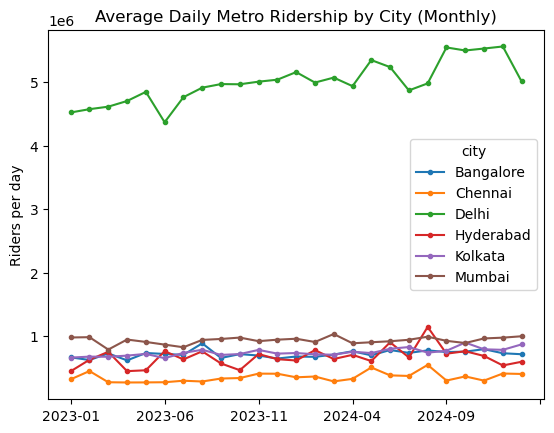

In [34]:
# monthly metro ridership trend by city (line)
m = df[df["mode"] == "Metro"].groupby(["year_month", "city"])["daily_ridership"].mean().unstack()
m.plot(marker="o", markersize=3)
plt.title("Average Daily Metro Ridership by City (Monthly)")
plt.ylabel("Riders per day"); plt.xlabel("")



(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'Bangalore'),
  Text(1, 0, 'Chennai'),
  Text(2, 0, 'Delhi'),
  Text(3, 0, 'Hyderabad'),
  Text(4, 0, 'Kolkata'),
  Text(5, 0, 'Mumbai')])

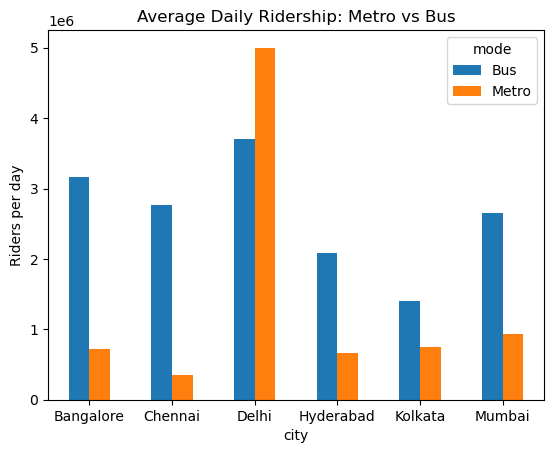

In [35]:
# average ridership city vs mode (grouped bar)
avg_city_mode.plot(kind="bar")
plt.title("Average Daily Ridership: Metro vs Bus"); plt.ylabel("Riders per day"); plt.xticks(rotation=0)


Text(0.5, 0, '% growth')

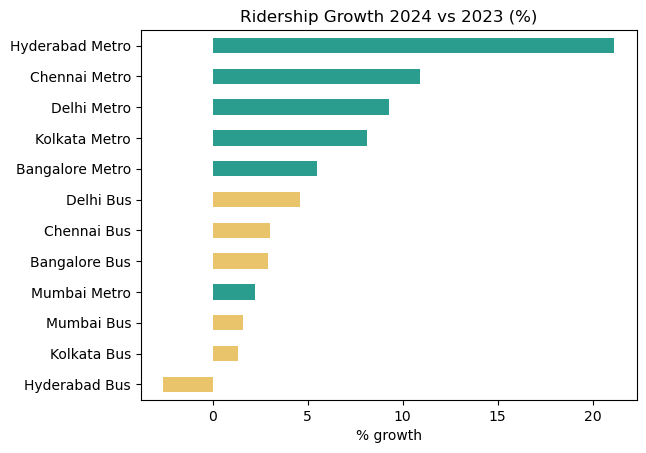

In [36]:
#YoY growth (horizontal bar)
g = yearly["growth_pct"].sort_values()
g.index = [f"{c} {md}" for c, md in g.index]
g.plot(kind="barh", color=["#2a9d8f" if "Metro" in i else "#e9c46a" for i in g.index])
plt.title("Ridership Growth 2024 vs 2023 (%)"); plt.xlabel("% growth")


Text(0.5, 0, 'Month')

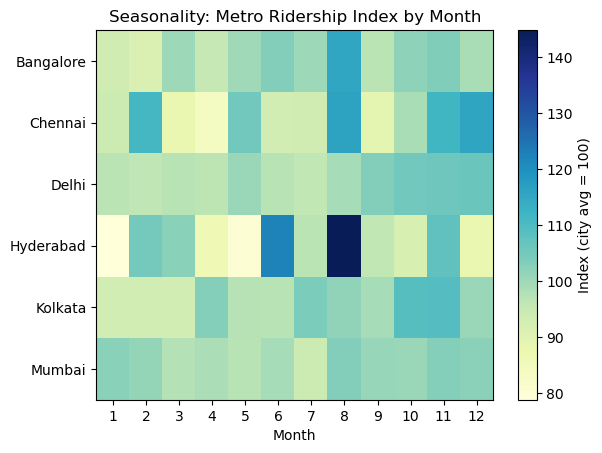

In [42]:
#  heatmap month x city for metro (matplotlib only)
hm = df[df["mode"] == "Metro"].pivot_table(index="city", columns="month", values="daily_ridership", aggfunc="mean")
hm = hm.div(hm.mean(axis=1), axis=0) * 100
fig, ax = plt.subplots()
im = ax.imshow(hm.values, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13)); ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
ax.grid(False); plt.colorbar(im, label="Index (city avg = 100)")
ax.set_title("Seasonality: Metro Ridership Index by Month"); ax.set_xlabel("Month")


Text(0, 0.5, 'INR')

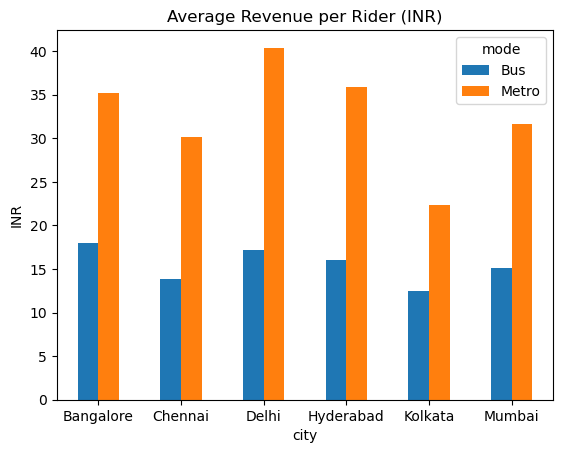

In [43]:
#  revenue per rider
kpi["revenue_per_rider"].unstack().plot(kind="bar")
plt.title("Average Revenue per Rider (INR)"); plt.xticks(rotation=0); plt.ylabel("INR")


Text(0, 0.5, 'On-time %')

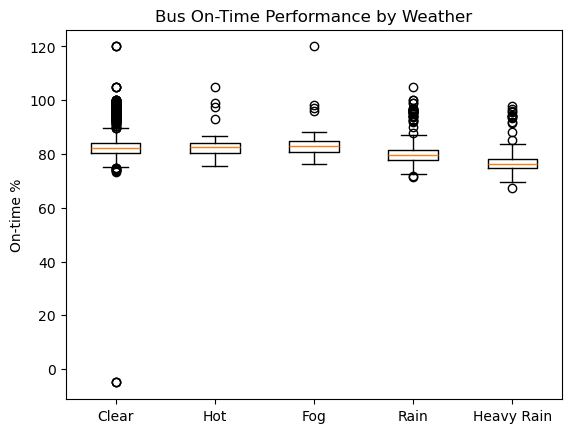

In [44]:
#on-time % by weather (box plot)
order = ["Clear", "Hot", "Fog", "Rain", "Heavy Rain"]
bus = df[df["mode"] == "Bus"]
plt.boxplot([bus[bus.weather == o]["on_time_pct"] for o in order])
plt.xticks(range(1, len(order) + 1), order)
plt.title("Bus On-Time Performance by Weather"); plt.ylabel("On-time %")


Text(0, 0.5, '%')

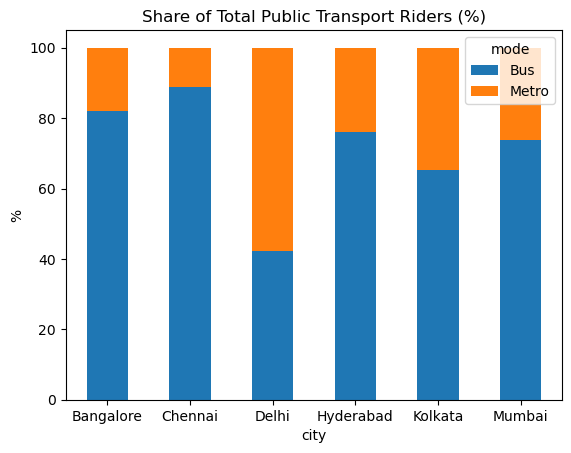

In [45]:
# metro share of total ridership (stacked bar)
share = df.groupby(["city", "mode"])["daily_ridership"].sum().unstack()
(share.div(share.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True)
plt.title("Share of Total Public Transport Riders (%)"); plt.xticks(rotation=0); plt.ylabel("%")


Text(0.5, 1.0, 'Correlation Matrix (Metro)')

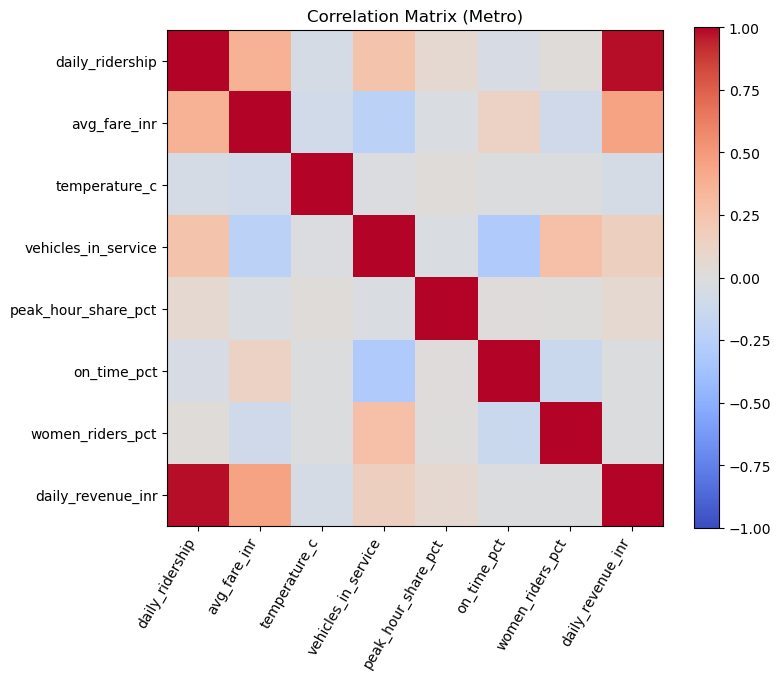

In [46]:
#correlation heatmap (metro)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr_metro.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=60, ha="right")
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols); ax.grid(False)
plt.colorbar(im); ax.set_title("Correlation Matrix (Metro)")
